# Recommendation to the director

**Final project · Intelligent museum guide** · issue #10

The kiosks run on **modest CPUs**, the team is **small** and the budget is **limited**. The director asks: **is a
neural network worth it in production, or would a simpler classical model do the job?**

This notebook trains nothing. It gathers what the other notebooks measured on the same 225 test paintings: the
accuracy (`baseline`, `mlp`, `resnet`), and the CPU time per painting and the size of the saved model
(`benchmark`). It puts them in **one table** and **one figure**, accuracy against CPU time, so the trade-off can be
read at a glance. It needs neither the data nor the weights, only `results/`: run it last.

**How this notebook is organised**

- From `src/`: `RESULTS_DIR`.
- It reads `results/benchmark.csv` (one line per model, with the accuracy the benchmark checked against the other
  notebooks), and `results/baseline.json` and `results/resnet.json` for the majority class and the validation
  accuracies.
- Defined here: `standard_error(accuracy)`, how much an accuracy measured on 225 paintings can move by chance.
- `models` holds one line per candidate model; the figure is saved in `results/recommendation.png`.

In [1]:
import csv
import json
import math
import sys

import matplotlib.pyplot as plt

sys.path.append("..")
from src.train import RESULTS_DIR

N_TRAIN, N_TEST = 1050, 225    # paintings of the shared split, the same for every model

with open(RESULTS_DIR / "benchmark.csv", newline="") as f:
    models = [row for row in csv.DictReader(f) if row["accuracy"]]   # the 224 px line is a cost only
for row in models:
    for key in ["n_params", "size_mb", "ms_per_image", "accuracy", "macro_f1", "train_time_s"]:
        row[key] = float(row[key])
baseline = json.loads((RESULTS_DIR / "baseline.json").read_text())
resnet = json.loads((RESULTS_DIR / "resnet.json").read_text())


def standard_error(accuracy, n=N_TEST):
    """Standard error of an accuracy measured on n paintings: sqrt(p (1 - p) / n)."""
    return math.sqrt(accuracy * (1 - accuracy) / n)


print(f"{len(models)} models, {N_TEST} test paintings")

5 models, 225 test paintings


## 1. One table: accuracy, cost and maintenance

For each model: the accuracy and the macro-F1 on the test set, with the standard error of the accuracy; the CPU
time per painting (median, one thread, batch of 1) and the size of the saved model, from the benchmark; the
training time, from `results/`, with the device it ran on.

The director also asked about a small team. The last part, **what an update needs**, is the work when the
collection changes (a new style, new paintings). It follows from how each model is trained; the only number in it,
the time to extract the ResNet features of the training paintings on one core, is the benchmark time multiplied by
1 050.

In [2]:
print(f"{'model':48s} {'accuracy':>14s} {'macro-F1':>8s} {'ms/painting':>11s} {'MB':>7s} {'training':>12s}")
for row in models:
    accuracy = f"{row['accuracy']:.3f} ± {standard_error(row['accuracy']):.3f}"
    training = f"{row['train_time_s']:.2g} s {row['train_device']}"
    print(f"{row['model']:48s} {accuracy:>14s} {row['macro_f1']:8.3f} {row['ms_per_image']:11.3f} "
          f"{row['size_mb']:7.3f} {training:>12s}")
print(f"{'Majority class (does not look at the image)':48s} {baseline['majority']['accuracy']:6.3f}")

finetuned = next(row for row in models if "fine-tuned" in row["model"])
features = next(row for row in models if "features" in row["model"])
update = {
    "Logistic regression, pixels (16 px)": "refit on a CPU in under a second",
    "Logistic regression, colour histograms (8 bins)": "refit on a CPU in under a second",
    "MLP, 3 × 512 (32 px)": "retrain on a CPU in a few seconds, check the early stopping",
    "ResNet-18 fine-tuned (128 px)": "retrain the 11 million weights on a GPU, check the early stopping, "
                                     "send a new 45 MB model to every kiosk",
    "ResNet-18 features + logistic regression": "the ImageNet backbone never changes: extract the features of the "
                                                f"new paintings (1 050 paintings: {N_TRAIN * features['ms_per_image'] / 1000:.0f} s "
                                                "on one CPU core), refit the logistic regression in under a second",
}
print("\nWhat an update needs")
for row in models:
    print(f"  {row['model']:48s} {update[row['model']]}")

whole = resnet["variants"]["whole network"]
print(f"\nfine-tuned - features: {finetuned['accuracy'] - features['accuracy']:+.3f} on the test set, "
      f"{whole['val_acc'] - resnet['logreg_features']['val_accuracy']:+.3f} on validation "
      f"({whole['val_acc']:.3f} ± {whole['val_acc_std']:.3f} over 3 seeds against "
      f"{resnet['logreg_features']['val_accuracy']:.3f})")

model                                                  accuracy macro-F1 ms/painting      MB     training
Logistic regression, pixels (16 px)               0.369 ± 0.032    0.339       0.073   0.016  0.012 s cpu
Logistic regression, colour histograms (8 bins)   0.396 ± 0.033    0.380       0.175   0.002   0.19 s cpu
MLP, 3 × 512 (32 px)                              0.440 ± 0.033    0.432       0.082   8.408    1.5 s cpu
ResNet-18 fine-tuned (128 px)                     0.804 ± 0.026    0.802       4.611  44.790     15 s mps
ResNet-18 features + logistic regression          0.769 ± 0.028    0.769       4.760  44.800    0.3 s mps
Majority class (does not look at the image)       0.200

What an update needs
  Logistic regression, pixels (16 px)              refit on a CPU in under a second
  Logistic regression, colour histograms (8 bins)  refit on a CPU in under a second
  MLP, 3 × 512 (32 px)                             retrain on a CPU in a few seconds, check the early stopping
  ResNe

## 2. Accuracy against CPU time

One point per model: the CPU time per painting on the horizontal axis, in log scale because the models span two
orders of magnitude, and the test accuracy on the vertical axis, with a bar of ± 1 standard error. The dotted line
is the majority class, which does not look at the image.

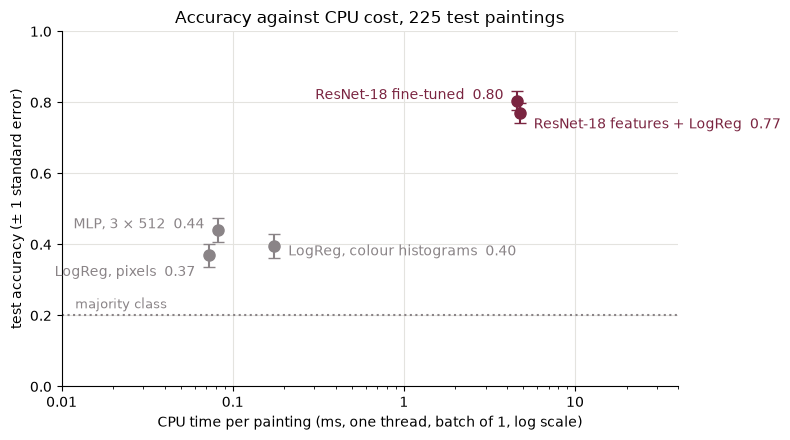

In [3]:
labels = {   # short name on the figure, and where to write it next to the dot (in points)
    "Logistic regression, pixels (16 px)": ("LogReg, pixels", (-10, -12), "right"),
    "Logistic regression, colour histograms (8 bins)": ("LogReg, colour histograms", (10, -4), "left"),
    "MLP, 3 × 512 (32 px)": ("MLP, 3 × 512", (-10, 4), "right"),
    "ResNet-18 fine-tuned (128 px)": ("ResNet-18 fine-tuned", (-10, 4), "right"),
    "ResNet-18 features + logistic regression": ("ResNet-18 features + LogReg", (10, -8), "left"),
}
fig, ax = plt.subplots(figsize=(8, 4.5))
for row in models:
    colour = "#7a2440" if row["model"].startswith("ResNet") else "#8a8487"   # ResNet features vs pixels or colours
    ax.errorbar(row["ms_per_image"], row["accuracy"], yerr=standard_error(row["accuracy"]), fmt="o", color=colour,
                markersize=8, capsize=4)
    name, offset, align = labels[row["model"]]
    ax.annotate(f"{name}  {row['accuracy']:.2f}", (row["ms_per_image"], row["accuracy"]), xytext=offset,
                textcoords="offset points", ha=align, va="center", fontsize=10, color=colour)
ax.axhline(baseline["majority"]["accuracy"], color="#8a8487", linestyle=":")
ax.text(0.012, baseline["majority"]["accuracy"] + 0.02, "majority class", fontsize=9, color="#8a8487")
ax.set_xscale("log")
ax.set_xlim(0.01, 40)
ax.set_xticks([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"])   # plain numbers rather than powers of 10
ax.set_ylim(0, 1)
ax.set_xlabel("CPU time per painting (ms, one thread, batch of 1, log scale)")
ax.set_ylabel("test accuracy (± 1 standard error)")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title("Accuracy against CPU cost, 225 test paintings")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "recommendation.png", dpi=120)
plt.show()

**What we see.**

- **Two groups, far apart.** Every model that only sees pixels or colours, the MLP included, stays between 0.37
  and 0.44: it is wrong more than half the time. The two models built on ResNet-18 features reach 0.77 and 0.80.
  The gap, more than 30 points, is far beyond the standard error of about 3 points: it is not noise.
- **The price of that gap is 4.6 to 4.8 ms per painting instead of 0.1 to 0.2 ms**, 25 to 65 times more, but still
  about 200 paintings per second on one core. A visitor cannot tell 0.1 ms from 5 ms.
- **The two ResNet options cost the same.** Fine-tuning is 3.5 points more accurate on the test set, about one
  standard error. The validation set points the same way (+5.6 points), so it is probably a real but small gain;
  225 paintings are not enough to measure it precisely.

## What we take from it

- **A neural network is worth it, for its pretrained features.** No model on pixels or colours, the MLP included,
  reaches a level a guide could use. The features of a ResNet-18 pretrained on ImageNet nearly double the accuracy,
  for a CPU cost a kiosk can afford.
- **We recommend the frozen features with a logistic regression**, rather than the fine-tuned network. It costs the
  same on the kiosk and is a few points less accurate. But the backbone never changes: updating the collection
  means refitting a logistic regression in seconds on a CPU, instead of a GPU run to watch and a new 45 MB model
  for every kiosk. For a small team, it is the option with the least to maintain.
- The recommendation, with its conditions and its limits, is in the project README, section *Recommendation to
  the director*. The figure `results/recommendation.png` is used on the slides.